# Feature detection -- SDSS J172637.24+264127.6

Goal: find the significant absorption features of the SDSS spectrum of the
A0 star, starting from the continuum fit of `continuum_fit_pablo.ipynb`, with
`detect.find_features`.

Method: after dividing by the continuum, a Gaussian as wide as the LSF (the
shape of an unresolved line) is slid along the spectrum. At each pixel it
gives the significance, in sigma, of a line centred there. A feature is a
group of neighbouring pixels above 1 sigma that contains at least one pixel
above the detection threshold, so a Balmer line with its wings is one
feature. The centre of each feature and its error come from a Gaussian fit
to the pixels of its window.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table

from spectral_diag.continuum import fit_continuum
from spectral_diag.constants import C_KMS
from spectral_diag.detect import find_features
from spectral_diag.sdss_reader import read_sdss_spec

## Data and continuum

Same spectrum and default continuum fit as in `05_continuum.ipynb`.
`find_features` needs the fitted continuum in `spec.continuum`, and the LSF
width in `spec.meta["fwhm_kms"]` (filled in by `read_sdss_spec`).

In [2]:
spec = read_sdss_spec(Path("../data/mast/spec-lite-2182-53905-0101.fits"))
spec = replace(spec, continuum=fit_continuum(spec).continuum)

print(f"{spec.meta['class']} {spec.meta['subclass']}, z = {spec.meta['z']:.5f}")
print(f"LSF FWHM: {spec.meta['fwhm_kms']:.1f} km/s")

STAR A0, z = -0.00012
LSF FWHM: 145.5 km/s


## Detection

Threshold of 4 sigma. The table has one row per feature: centre `wave` and
its error (Gaussian fit), window (`wave_min`, `wave_max`), `depth` (fraction
of the continuum absorbed at the deepest pixel), equivalent width `ew` with
its error, and `snr` = `ew` / `ew_err`. Wavelengths in Angstrom.

In [3]:
THRESHOLD = 4.0
DECIMALS = ".2f"

features = find_features(spec, threshold=THRESHOLD)
for name in features.colnames:
    features[name].format = DECIMALS
print(f"{len(features)} features above {THRESHOLD:.0f} sigma")
features.pprint(max_lines=-1)

39 features above 4 sigma
  wave  wave_err wave_min wave_max depth   ew  ew_err  snr  
------- -------- -------- -------- ----- ----- ------ ------
3814.81     0.31  3813.29  3815.93  0.06  0.11   0.03   4.45
3836.20     0.13  3821.20  3853.01  0.71  8.87   0.08 115.43
3858.76     0.38  3854.78  3862.78  0.10  0.54   0.05  11.23
3889.81     0.25  3871.68  3908.41  0.71 10.46   0.08 131.02
3970.41     0.55  3928.26  4007.74  0.79 16.00   0.12 131.46
4102.37     0.26  4068.18  4137.14  0.72 13.69   0.11 121.06
4144.37     0.49  4141.90  4145.72  0.04  0.13   0.03   4.38
4173.60     0.39  4171.57  4183.12  0.06  0.33   0.05   6.23
4227.34     0.31  4225.71  4228.63  0.05  0.12   0.02   4.72
4341.19     0.28  4288.45  4377.24  0.69 14.15   0.13 105.64
4384.96     0.39  4383.29  4387.33  0.06  0.19   0.03   6.33
4395.71     0.23  4394.40  4397.44  0.07  0.14   0.03   5.43
4417.50     0.26  4414.69  4419.77  0.07  0.23   0.03   6.90
4444.45     0.28  4442.22  4446.31  0.06  0.15   0.03   4.8

The seven Balmer lines (H9 to H-alpha) are the deepest features (depth
0.5-0.8) and have the widest windows (30-100 A). Some windows contain more
than one line:

- The window of H-epsilon (3928-4008 A) also contains the CaII K and H
  lines (about 3934 and 3969 A), blended with it.
- The window at 8640-8794 A (large `ew_err`) holds several blended lines
  (Paschen and CaII).
- The window at 5886-5903 A covers the NaI D doublet as one feature.
- The feature at 7598 A is probably the telluric O2 A band.

The weak features (EW of a few tenths of an Angstrom) are the ones close to
the threshold. A few of them have a `wave_err` of several Angstrom (4585,
5184 and 8445 A), where the fit of the centre is poorly constrained.

## Detected features on the spectrum

Orange bands: window of each feature. Red lines: centre.

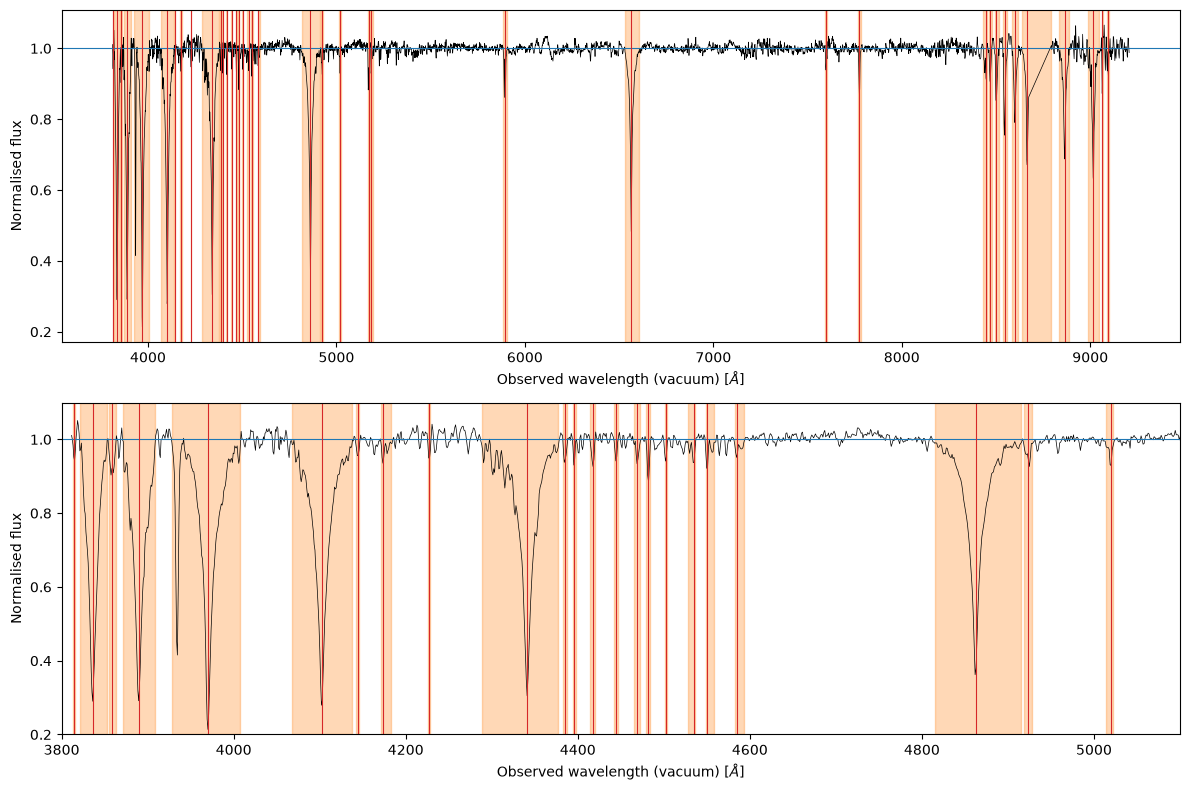

In [4]:
BLUE_WAVE_RANGE = (3800, 5100)
NORMALISED_FLUX_RANGE = (0.2, 1.1)


def plot_features(ax, spec, features):
    """Plot the normalised flux with the window and centre of each feature.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    spec : Spectrum
        With `continuum` set.
    features : astropy.table.Table
        Output of `find_features`.
    """
    ax.plot(spec.wave, spec.flux / spec.continuum, lw=0.5, color="k")
    ax.axhline(1, color="C0", lw=0.8)
    for feature in features:
        ax.axvspan(feature["wave_min"], feature["wave_max"], color="C1", alpha=0.3)
        ax.axvline(feature["wave"], color="C3", lw=0.8)
    ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
    ax.set_ylabel("Normalised flux")


fig, (ax_full, ax_blue) = plt.subplots(2, 1, figsize=(12, 8))
plot_features(ax_full, spec, features)
plot_features(ax_blue, spec, features)
ax_blue.set_xlim(*BLUE_WAVE_RANGE)
ax_blue.set_ylim(*NORMALISED_FLUX_RANGE)
plt.tight_layout()
plt.show()

## Check against the Balmer series

The strongest features should be the hydrogen Balmer lines, at their rest
wavelength shifted by the redshift of the star in the SDSS catalogue
(`z` = -0.00012, about -37 km/s). Rest wavelengths in vacuum, from the
Rydberg formula.

In [5]:
BALMER_REST_WAVES = {
    "H9": 3836.47,
    "H8": 3890.16,
    "H-epsilon": 3971.20,
    "H-delta": 4102.89,
    "H-gamma": 4341.69,
    "H-beta": 4862.68,
    "H-alpha": 6564.61,
}


def compare_with_expected(features, rest_waves, z):
    """Offset between the nearest feature and each expected line.

    Parameters
    ----------
    features : astropy.table.Table
        Output of `find_features`.
    rest_waves : dict
        Line name -> rest wavelength in vacuum, Angstrom.
    z : float
        Redshift of the star.

    Returns
    -------
    comparison : astropy.table.Table
        Expected and measured wavelength (Angstrom), their difference
        (Angstrom and km/s) and the error of the measured centre.
    """
    rows = []
    for name, wave_rest in rest_waves.items():
        expected = wave_rest * (1 + z)
        nearest = features[np.argmin(np.abs(features["wave"] - expected))]
        offset = nearest["wave"] - expected
        rows.append(
            (name, expected, nearest["wave"], offset, C_KMS * offset / expected,
             nearest["wave_err"])
        )
    names = ("line", "expected", "measured", "offset", "offset_kms", "wave_err")
    return Table(rows=rows, names=names)


comparison = compare_with_expected(features, BALMER_REST_WAVES, spec.meta["z"])
for name in comparison.colnames[1:]:
    comparison[name].format = DECIMALS
comparison.pprint(max_lines=-1)

   line   expected measured offset offset_kms wave_err
--------- -------- -------- ------ ---------- --------
       H9  3836.00  3836.20   0.20      15.87     0.13
       H8  3889.68  3889.81   0.12       9.62     0.25
H-epsilon  3970.71  3970.41  -0.30     -23.00     0.55
  H-delta  4102.38  4102.37  -0.01      -0.78     0.26
  H-gamma  4341.16  4341.19   0.04       2.44     0.28
   H-beta  4862.08  4862.29   0.21      13.15     0.28
  H-alpha  6563.80  6564.36   0.56      25.36     0.37


All the offsets are below 0.6 A (about 25 km/s), a sixth of the resolution
(145 km/s), and within 2 times `wave_err` (0.13-0.55 A). A Gaussian fits the
Balmer lines poorly (reduced chi^2 of 8 to 165), so the error of their
centre is multiplied by the square root of that (3 to 13): see Limitations.

## Detection threshold

How many features survive as the threshold rises. The weak ones (a few
tenths of an Angstrom of EW) are the first to go; the Balmer lines stay.
Features per threshold:

In [6]:
THRESHOLDS = [4.0, 5.0, 6.0, 8.0, 10.0, 20.0]

for threshold in THRESHOLDS:
    n_features = len(find_features(spec, threshold=threshold))
    print(f"threshold {threshold:4.1f} sigma: {n_features:3d} features")

threshold  4.0 sigma:  39 features
threshold  5.0 sigma:  35 features


threshold  6.0 sigma:  28 features
threshold  8.0 sigma:  20 features


threshold 10.0 sigma:  17 features
threshold 20.0 sigma:  12 features


The number of features drops from 39 to 12 between 4 and 20 sigma.

## Limitations

- `wave` and `wave_err` come from a Gaussian fit to the window, evaluated at
  the pixel centres. A Gaussian is not the shape of a broad line with
  damping wings: for the Balmer lines (reduced chi^2 of 8 to 165) the error
  is scaled up by the square root of the reduced chi^2 and is only a loose
  bound. It ignores blends and the uncertainty of the redshift of the star.
- The window of a broad line misses its far wings, so `ew` is meant for
  detecting and locating, not for the curve of growth (in the synthetic
  tests, about 6% of the EW of a Balmer-like line is lost).
- Blended lines can end up in the same feature (H-epsilon with CaII H and
  K).
- The window edge (1 sigma) is not calibrated; see the TODO in
  `detect/significance.py`.
- The error of the continuum is not included in the significance.
- The physical Voigt fit of the lines (N, b, z, with the LSF) is a later
  stage, on the identified lines.
- Telluric bands are not masked yet, and the hydrogen rest wavelengths are
  written here by hand until `linelist` has the hydrogen comb.